In [7]:
import numpy as np 
import matplotlib.pyplot as plt 

path = "/home/rvstxm/cylinder-ml/cases/cylinder_Re100_bw_sf9/postProcessing/forceCoeffsIncompressible/0/forceCoeffs.dat"
data = np.loadtxt(path, comments="#")
print(data.shape)

(47466, 6)


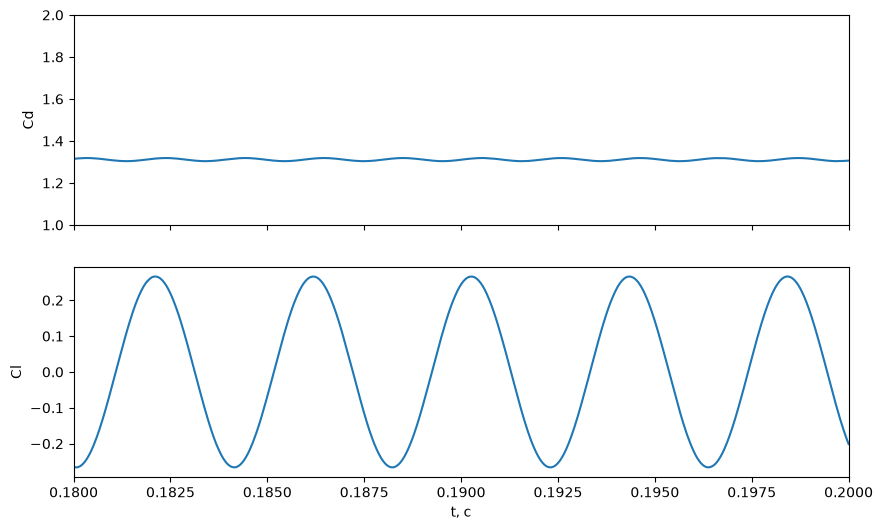

In [13]:
t = data[:, 0]
Cd = data[:, 2]
Cl = data[:, 3]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10,6), sharex=True)
ax1.plot(t, Cd)
ax1.set_ylabel("Cd")
ax1.set_ylim(1.2, 1.4)
ax2.set_xlim(0.18, 0.20)
ax1.set_ylim(1, 2)
ax2.plot(t, Cl)
ax2.set_ylabel("Cl")
ax2.set_xlabel("t, c")
plt.show()

In [14]:
mask = t > 0.11
t_s = t[mask]
Cd_s = Cd[mask]
Cl_s = Cl[mask]


In [15]:
Cd_mean = np.mean(Cd_s)
Cl_amp = (np.max(Cl_s) - np.min(Cl_s)/2)

print(f'Cd_mean = {Cd_mean:.4f}')
print(f'Cl_amp = {Cl_amp:.4f}')

Cd_mean = 1.3112
Cl_amp = 0.3994


найдено пиков: 22
f = 245.1 Гц
St = 0.1634


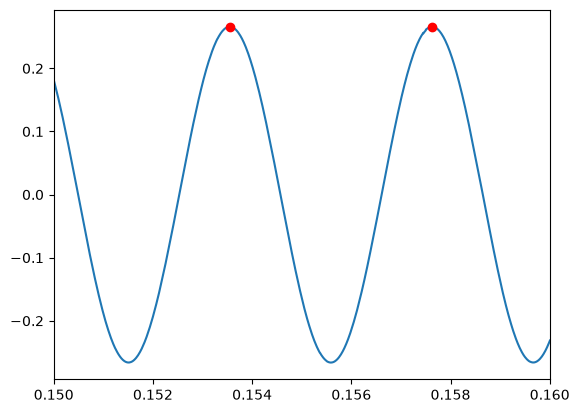

In [16]:
from scipy.signal import find_peaks

peaks, _ = find_peaks(Cl_s, prominence=0.1)
t_peaks = t_s[peaks]

print("найдено пиков:", len(peaks))

T = np.mean(np.diff(t_peaks))
f = 1/T
D, U = 0.001, 1.5
St = (f * D)/U

print(f"f = {f:.1f} Гц")
print(f"St = {St:.4f}")

plt.plot(t_s, Cl_s)
plt.plot(t_peaks, Cl_s[peaks], "ro")   # найденные пики красными точками
plt.xlim(0.15, 0.16)                   # приблизим пару периодов
plt.show()

In [17]:
St_lit = -3.3265/100 + 0.1816 + 1.6e-04 * 100
Cd_lit = 1.33 

err_St = (St - St_lit)/St_lit * 100
err_Cd = (Cd_mean - Cd_lit)/Cd_lit * 100

print(f"ошибка St: {err_St:+.1f}%")
print(f"ошибка Cd: {err_Cd:+.1f}%")


ошибка St: -0.6%
ошибка Cd: -1.4%
